# LDA Projection (Fisher's Linear Discriminant)

PCA (`34_pca`) keeps the directions of **largest variance** and never looks at the labels — so it can happily keep a direction that is all noise. LDA is the **supervised** alternative: it picks the directions that best **separate the classes**.

(`14_discriminant_analysis` uses the same maths as a classifier. This folder uses it to *reduce dimensions*.)

## How it works

1. Within-class scatter `Sw = Σ_c Σ_{x∈c} (x − μ_c)(x − μ_c)ᵀ` — how spread out each class is.
2. Between-class scatter `Sb = Σ_c n_c (μ_c − μ)(μ_c − μ)ᵀ` — how far apart the class means are.
3. Find directions `w` maximising the **Fisher ratio** `wᵀSb w / wᵀSw w`. That is the generalized eigenproblem `Sb w = λ Sw w`.
4. To solve it with a plain symmetric eigensolver: `Sw = L Lᵀ` (Cholesky), eigendecompose `L⁻¹ Sb L⁻ᵀ`, map back with `w = L⁻ᵀ v`. Each `w` is scaled so `wᵀSw w = 1`.
5. Keep the top eigenvectors. **At most `C − 1`** are useful (`Sb` has rank ≤ `C − 1`) — 3 classes give a 2-D view.

The eigenvalue `λ` is the Fisher ratio that direction achieves, so `eigenvalues_` tells you how much separation each axis carries.

Use it when you have labels and want a small, class-aware embedding (visualisation, preprocessing before kNN). Assumes classes are roughly Gaussian with similar covariance; needs more samples than features for a stable `Sw`.

## Usage

```python
# (the class is defined in the Implementation section below)

lda = LDAProjection(n_components=2).fit(X, y)
Z = lda.transform(X)
lda.eigenvalues_, lda.explained_variance_ratio_
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class LDAProjection:
    """Fisher's Linear Discriminant Analysis as a SUPERVISED dimensionality reduction.

    PCA keeps the directions of largest variance and ignores the labels. LDA uses the labels: it
    finds directions w that maximise  (between-class scatter) / (within-class scatter) =
    w'Sb w / w'Sw w, i.e. directions along which the class means are far apart relative to how
    spread out each class is.

    With C classes there are at most C-1 useful directions. They solve the generalized eigenproblem
    Sb w = lambda Sw w; here it is turned into an ordinary symmetric one with the Cholesky factor
    Sw = L L': eigenvectors v of L^-1 Sb L^-T give w = L^-T v, scaled so w' Sw w = 1.

    (14_discriminant_analysis uses the same maths as a classifier; this one is the projection.)"""

    def __init__(self, n_components=None, reg=0.0):
        self.n_components = n_components  # None -> C - 1
        self.reg = reg                     # ridge (relative to trace) if Sw is singular, e.g. 1e-6

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        classes = np.unique(y)
        d = X.shape[1]
        k = self.n_components or len(classes) - 1
        if k > min(len(classes) - 1, d):
            raise ValueError("n_components cannot exceed min(n_classes - 1, n_features)")

        self.mean_ = X.mean(axis=0)
        Sw = np.zeros((d, d))
        Sb = np.zeros((d, d))
        for c in classes:
            Xc = X[y == c]
            mean_c = Xc.mean(axis=0)
            Sw += (Xc - mean_c).T @ (Xc - mean_c)
            diff = (mean_c - self.mean_)[:, None]
            Sb += len(Xc) * (diff @ diff.T)
        Sw += self.reg * np.trace(Sw) / d * np.eye(d)

        L = np.linalg.cholesky(Sw)
        L_inv = np.linalg.inv(L)
        eigenvalues, V = np.linalg.eigh(L_inv @ Sb @ L_inv.T)
        order = np.argsort(eigenvalues)[::-1][:k]
        self.eigenvalues_ = eigenvalues[order]  # Fisher ratio achieved by each direction
        self.explained_variance_ratio_ = self.eigenvalues_ / eigenvalues.clip(min=0).sum()
        self.components_ = (L_inv.T @ V[:, order]).T  # rows are the discriminant directions
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) @ self.components_.T

    def fit_transform(self, X, y):
        return self.fit(X, y).transform(X)

## See it work

### 1. Supervised direction vs highest-variance direction

Two classes that differ only along `y`, while the data is wildly spread along `x`. PCA (which ignores labels) picks the `x` axis because that is where the variance is, and the classes overlap completely on it. LDA picks the direction that **separates the class means relative to the within-class spread**.

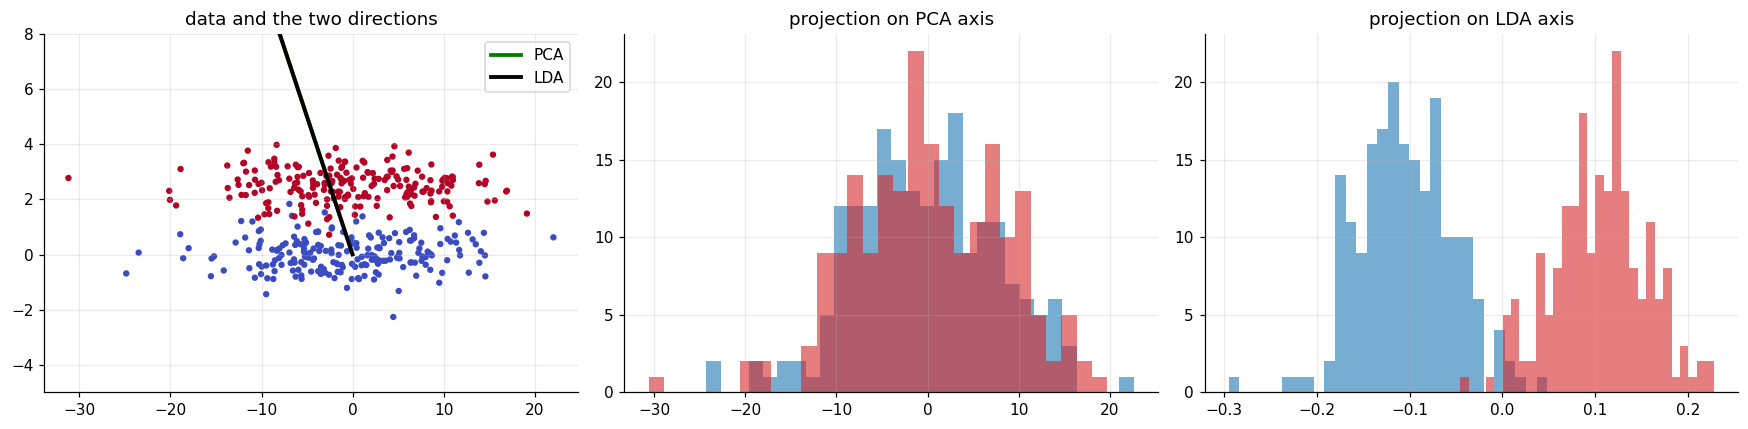

In [3]:
from sklearn.decomposition import PCA as SkPCA

rng = np.random.default_rng(0)
X = np.vstack([rng.normal([0, 0], [8.0, 0.6], size=(200, 2)), rng.normal([0, 2.5], [8.0, 0.6], size=(200, 2))]); y = np.array([0] * 200 + [1] * 200)
lda = LDAProjection(n_components=1).fit(X, y); pca = SkPCA(1).fit(X)
z_lda = lda.transform(X)[:, 0]; z_pca = pca.transform(X)[:, 0]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(*X.T, c=y, cmap="coolwarm", s=10)
for vec, c, n in [(pca.components_[0], "g", "PCA"), (lda.components_[0] / np.linalg.norm(lda.components_[0]), "k", "LDA")]:
    axes[0].plot(*np.c_[-12 * vec, 12 * vec].T, c=c, lw=2.5, label=n)
axes[0].set(title="data and the two directions", ylim=(-5, 8)); axes[0].legend()
for ax, z, n in [(axes[1], z_pca, "PCA"), (axes[2], z_lda, "LDA")]:
    ax.hist(z[y == 0], bins=30, alpha=0.6, color="C0"); ax.hist(z[y == 1], bins=30, alpha=0.6, color="C3"); ax.set_title(f"projection on {n} axis")
plt.tight_layout(); plt.show()

### 2. Wine: three classes into 2-D

LDA can produce at most `classes − 1` directions: two for three classes. On the standardised wine data, PCA mixes the three cultivars more than LDA does, because LDA uses the labels.

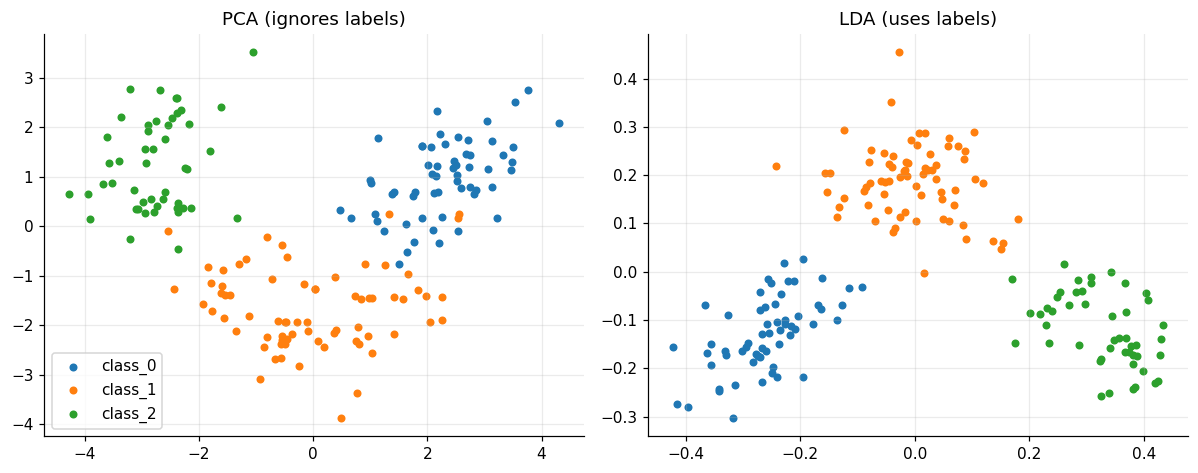

In [4]:
from sklearn.datasets import load_wine

wine = load_wine(); Xw = (wine.data - wine.data.mean(0)) / wine.data.std(0)
Zp = SkPCA(2).fit_transform(Xw); Zl = LDAProjection().fit_transform(Xw, wine.target)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, Z, n in [(axes[0], Zp, "PCA (ignores labels)"), (axes[1], Zl, "LDA (uses labels)")]:
    for c, name in enumerate(wine.target_names): ax.scatter(*Z[wine.target == c].T, s=18, label=name)
    ax.set_title(n)
axes[0].legend(); plt.tight_layout(); plt.show()

### 3. How much separation each direction carries

`eigenvalues_` are the Fisher ratios (between-class over within-class scatter) of each direction; `explained_variance_ratio_` normalises them. The first axis does most of the work.

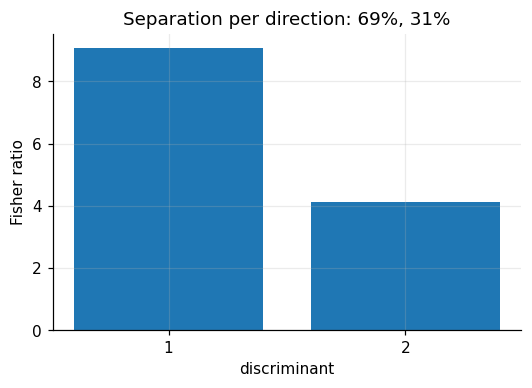

In [5]:
m = LDAProjection().fit(Xw, wine.target)
plt.figure(figsize=(5.5, 3.5)); plt.bar([1, 2], m.eigenvalues_); plt.xticks([1, 2]); plt.xlabel("discriminant"); plt.ylabel("Fisher ratio")
plt.title("Separation per direction: " + ", ".join(f"{r:.0%}" for r in m.explained_variance_ratio_)); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

data = load_wine()
X, y = data.data, data.target

ours = LDAProjection().fit(X, y)
theirs = LinearDiscriminantAnalysis(solver="eigen", n_components=2).fit(X, y)

print("explained ratio: ours=%s sklearn=%s" % (ours.explained_variance_ratio_.round(4), theirs.explained_variance_ratio_.round(4)))
assert np.allclose(ours.explained_variance_ratio_, theirs.explained_variance_ratio_, atol=1e-6)

# scaling conventions differ, so compare each discriminant axis by correlation (sign-free)
a, b = ours.transform(X), theirs.transform(X)
for j in range(2):
    corr = abs(np.corrcoef(a[:, j], b[:, j])[0, 1])
    print("discriminant %d: |correlation with sklearn| = %.6f" % (j + 1, corr))
    assert corr > 0.9999

# why supervised matters: 2-D wine, 5-fold kNN accuracy
Xs = (X - X.mean(0)) / X.std(0)
knn = KNeighborsClassifier(5)
acc_lda = cross_val_score(knn, LDAProjection().fit_transform(Xs, y), y, cv=5).mean()
acc_pca = cross_val_score(knn, PCA(2).fit_transform(Xs), y, cv=5).mean()
print("kNN accuracy on 2-D embedding: LDA=%.3f  PCA=%.3f" % (acc_lda, acc_pca))

explained ratio: ours=[0.6875 0.3125] sklearn=[0.6875 0.3125]
discriminant 1: |correlation with sklearn| = 1.000000
discriminant 2: |correlation with sklearn| = 1.000000
kNN accuracy on 2-D embedding: LDA=0.994  PCA=0.966


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _two_stretched_blobs(seed=0, n=200):
    """Huge variance along x (useless), classes differ only along y (useful)."""
    rng = np.random.default_rng(seed)
    X = np.vstack([rng.normal([0, 0], [10.0, 0.5], size=(n, 2)), rng.normal([0, 3], [10.0, 0.5], size=(n, 2))])
    return X, np.array([0] * n + [1] * n)


def _fisher_ratio(z, y):
    between = (z[y == 0].mean() - z[y == 1].mean()) ** 2
    within = z[y == 0].var() + z[y == 1].var()
    return between / within


def test_finds_the_discriminative_axis_where_pca_picks_the_noisy_one():
    X, y = _two_stretched_blobs()
    lda = LDAProjection(n_components=1).fit_transform(X, y)[:, 0]
    # PCA's first direction = largest variance = the x axis
    Xc = X - X.mean(axis=0)
    pca = Xc @ np.linalg.eigh(np.cov(Xc, rowvar=False))[1][:, -1]
    assert _fisher_ratio(lda, y) > 10 * _fisher_ratio(pca, y)
    assert abs(LDAProjection(n_components=1).fit(X, y).components_[0][1]) > 0.99 * np.linalg.norm(
        LDAProjection(n_components=1).fit(X, y).components_[0]
    )  # points along y


def test_at_most_classes_minus_one_directions():
    rng = np.random.default_rng(1)
    X = rng.normal(size=(90, 5)) + np.repeat(np.eye(3, 5) * 4, 30, axis=0)
    y = np.repeat([0, 1, 2], 30)
    assert LDAProjection().fit_transform(X, y).shape == (90, 2)
    try:
        LDAProjection(n_components=3).fit(X, y)
        raise AssertionError("should reject 3 components for 3 classes")
    except ValueError:
        pass


def test_directions_are_whitened_and_uncorrelated_within_class():
    rng = np.random.default_rng(2)
    X = rng.normal(size=(150, 4)) @ rng.normal(size=(4, 4)) + np.repeat(rng.normal(size=(3, 4)) * 5, 50, axis=0)
    y = np.repeat([0, 1, 2], 50)
    model = LDAProjection().fit(X, y)
    Z = model.transform(X)
    Sw = sum((Z[y == c] - Z[y == c].mean(0)).T @ (Z[y == c] - Z[y == c].mean(0)) for c in range(3))
    assert np.allclose(Sw, np.eye(2), atol=1e-4)   # w' Sw w = 1 and cross terms 0
    assert (np.diff(model.eigenvalues_) <= 1e-12).all()

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_finds_the_discriminative_axis_where_pca_picks_the_noisy_one
PASS test_at_most_classes_minus_one_directions
PASS test_directions_are_whitened_and_uncorrelated_within_class

all 3 tests passed


## Takeaways

- **Use it** as a supervised dimensionality reduction (to 2-3 dimensions for plots, or as preprocessing before kNN/logistic regression). The same maths is the classifier in `14_discriminant_analysis`.
- **Method:** maximise `wᵀS_b w / wᵀS_w w`; solve the generalised eigenproblem (here via a Cholesky whitening of `S_w`); keep at most `C − 1` directions.
- **Pitfalls:** assumes roughly Gaussian classes with similar covariance; needs more samples than features for a stable `S_w` (use `reg`); limited to `C − 1` dimensions.
- **Interview line:** *"PCA maximises variance, LDA maximises between-class over within-class scatter, so it uses the labels and gives at most `C − 1` axes."*